In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# 18 — Final Results and Integration

This notebook collects results from all pipeline notebooks (07–17) into the final
comparison table, final figures, and a frozen record of the project. It does not
train any models.

**Inputs:** metrics and predictions from 07, 08, 12, 13, 14; explainability results (15);
ablation and error analysis (16); final inference (17).
**Outputs:** final comparison table, figures, manuscript-ready numbers, repo manifest.

In [3]:
import os
root = "/kaggle/input/notebooks"
for user in sorted(os.listdir(root)):
    for nb in sorted(os.listdir(f"{root}/{user}")):
        path = f"{root}/{user}/{nb}"
        print(f"\n=== {user}/{nb} ===")
        for dp, dn, fn in os.walk(path):
            depth = dp[len(path):].count("/")
            if depth > 2:          # don't go too deep
                continue
            for f in sorted(fn)[:15]:   # first 15 files per folder
                size = os.path.getsize(f"{dp}/{f}") / 1e6
                print(f"  {dp[len(path):] or '.'}/{f}  ({size:.1f} MB)")


=== minnieg12/07-efficientnet ===
  ./__notebook__.ipynb  (1.2 MB)
  ./__output__.json  (0.0 MB)
  ./__results__.html  (0.9 MB)
  ./custom.css  (0.0 MB)
  ./efficientnet_b0_all_history.csv  (0.0 MB)
  ./efficientnet_b0_comparison_row.csv  (0.0 MB)
  ./efficientnet_b0_fold_0.pth  (16.4 MB)
  ./efficientnet_b0_fold_1.pth  (16.4 MB)
  ./efficientnet_b0_fold_2.pth  (16.4 MB)
  ./efficientnet_b0_fold_3.pth  (16.4 MB)
  ./efficientnet_b0_fold_4.pth  (16.4 MB)
  ./efficientnet_b0_fold_results.csv  (0.0 MB)
  ./efficientnet_b0_metric_summary.csv  (0.0 MB)
  ./efficientnet_b0_oof_error_analysis.csv  (0.0 MB)
  ./efficientnet_b0_oof_per_class_metrics.csv  (0.0 MB)
  /__results___files/__results___24_0.png  (0.1 MB)
  /__results___files/__results___25_1.png  (0.0 MB)
  /__results___files/__results___26_0.png  (0.1 MB)
  /__results___files/__results___26_1.png  (0.1 MB)
  /__results___files/__results___6_0.png  (0.0 MB)

=== minnieg12/08-vit ===
  ./__huggingface_repos__.json  (0.0 MB)
  ./__note

In [5]:
import os, shutil, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

R = Path("/kaggle/input/notebooks")
P = {
 "07": R/"minnieg12/07-efficientnet",
 "08": R/"minnieg12/08-vit",
 "09": R/"minnieg12/09-dinov2",
 "10": R/"minnieg12/10-slice-mil",
 "11": R/"minnieg12/11-series-mil",
 "12": R/"richashanbhag/12-proposed-model/12_proposed_model",
 "13": R/"richashanbhag/13-weak-supervision/13_weak_supervision",
 "14": R/"richashanbhag/14-evaluation/14_evaluation",
 "15": R/"shambhavisinha254/15-explainability/15_explainability",
 "16": R/"shambhavisinha254/16-ablation-error/16_ablation_error",
 "17": R/"shambhavisinha254/17-final-inference/17_final_inference",
}
for d in ["tables", "figs"]:
    os.makedirs(f"/kaggle/working/{d}", exist_ok=True)

for k, p in P.items():
    print(k, "OK" if p.exists() else "MISSING", p)

07 OK /kaggle/input/notebooks/minnieg12/07-efficientnet
08 OK /kaggle/input/notebooks/minnieg12/08-vit
09 OK /kaggle/input/notebooks/minnieg12/09-dinov2
10 OK /kaggle/input/notebooks/minnieg12/10-slice-mil
11 OK /kaggle/input/notebooks/minnieg12/11-series-mil
12 OK /kaggle/input/notebooks/richashanbhag/12-proposed-model/12_proposed_model
13 OK /kaggle/input/notebooks/richashanbhag/13-weak-supervision/13_weak_supervision
14 OK /kaggle/input/notebooks/richashanbhag/14-evaluation/14_evaluation
15 OK /kaggle/input/notebooks/shambhavisinha254/15-explainability/15_explainability
16 OK /kaggle/input/notebooks/shambhavisinha254/16-ablation-error/16_ablation_error
17 MISSING /kaggle/input/notebooks/shambhavisinha254/17-final-inference/17_final_inference


In [11]:
key_files = {
 "07 comparison": P["07"]/"efficientnet_b0_comparison_row.csv",
 "08 comparison": P["08"]/"vit_s16_comparison_row.csv",
 "10 comparison": P["10"]/"dinov2_slice_attention_comparison_row.csv",
 "11 comparison": P["11"]/"dinov2_series_attention_comparison_row.csv",
 "12 comparison": P["12"]/"hierarchical_dinov2_comparison_row.csv",
 "13 fold metrics": P["13"]/"fold_metrics.csv",
 "14 overall": P["14"]/"overall_metrics.csv",
 "14 per finding": P["14"]/"per_finding_metrics.csv",
 "14 CI": P["14"]/"bootstrap_confidence_intervals.csv",
 "14 paired diff": P["14"]/"paired_bootstrap_differences.csv",
 "14 calibration": P["14"]/"calibration_metrics.csv",
 "14 interpretation": P["14"]/"statistical_interpretation.csv",
 "15 perturbation": P["15"]/"15_perturbation_summary.csv",
 "16 ablation": P["16"]/"16_pooling_ablation_comparison.csv",
 "16 robustness": P["16"]/"16_robustness_summary.csv",
 "16 errors": P["16"]/"16_error_counts_by_label.csv",
}
for name, path in key_files.items():
    df = pd.read_csv(path)
    print(f"{name:20s}", df.shape, df.columns.tolist())

07 comparison        (1, 24) ['model', 'input', 'aggregation', 'loss', 'threshold', 'folds_completed', 'macro_auc_mean', 'macro_auc_std', 'macro_pr_auc_mean', 'macro_pr_auc_std', 'macro_precision_mean', 'macro_precision_std', 'macro_recall_mean', 'macro_recall_std', 'macro_f1_mean', 'macro_f1_std', 'macro_specificity_mean', 'macro_specificity_std', 'micro_f1_mean', 'micro_f1_std', 'hamming_loss_mean', 'hamming_loss_std', 'subset_accuracy_mean', 'subset_accuracy_std']
08 comparison        (1, 10) ['model', 'macro_auc', 'macro_pr_auc', 'macro_precision', 'macro_recall', 'macro_f1', 'macro_specificity', 'micro_f1', 'hamming_loss', 'subset_accuracy']
10 comparison        (1, 13) ['model', 'macro_auc', 'macro_pr_auc', 'macro_precision', 'macro_recall', 'macro_f1', 'macro_specificity', 'micro_f1', 'hamming_loss', 'subset_accuracy', 'n_gold_studies', 'n_folds', 'threshold']
11 comparison        (1, 14) ['model', 'macro_auc', 'macro_pr_auc', 'macro_precision', 'macro_recall', 'macro_f1', 'macr

In [12]:
overall = pd.read_csv(P["14"]/"overall_metrics.csv")
display(overall)

# fallback: stack each notebook's own comparison row
rows = []
for k in ["07", "08", "10", "11", "12"]:
    f = [x for x in os.listdir(P[k]) if x.endswith("comparison_row.csv")][0]
    r = pd.read_csv(P[k]/f); r.insert(0, "notebook", k); rows.append(r)
stacked = pd.concat(rows, ignore_index=True)
display(stacked)

overall.to_csv("/kaggle/working/tables/final_comparison.csv", index=False)
stacked.to_csv("/kaggle/working/tables/final_comparison_stacked.csv", index=False)

,mode,macro_roc_auc,macro_pr_auc,macro_f1,macro_precision,macro_recall,macro_brier,macro_ece,hamming_loss,micro_f1,exact_match_accuracy
0,gold_only,0.470951,0.392358,0.226700,0.455417,0.182383,0.227244,0.140827,0.337644,0.330484,0.0
1,gold_plus_unweighted_weak,0.520096,0.396903,0.333171,0.357567,0.434800,0.258092,0.202638,0.413793,0.480144,0.0
2,gold_plus_confidence_weighted_weak,0.520096,0.396903,0.333171,0.357567,0.434800,0.258092,0.202638,0.413793,0.480144,0.0


,notebook,model,input,aggregation,loss,threshold,folds_completed,macro_auc_mean,macro_auc_std,macro_pr_auc_mean,...,macro_recall,macro_f1,macro_specificity,micro_f1,hamming_loss,subset_accuracy,n_gold_studies,n_folds,n_series,n_2p5d_instances
0,07,EfficientNet-B0,2.5D previous/current/next slices,mean instance-logit pooling,weighted BCE,0.5,5.0,0.535003,0.059622,0.523504,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,08,ViT-S/16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.296925,0.257234,0.748228,0.401413,0.365278,0.000000,NaN,NaN,NaN,NaN
2,10,DINOv2 ViT-S/14 + flat slice-attention MIL,NaN,NaN,NaN,0.5,NaN,NaN,NaN,NaN,...,0.372480,0.278984,0.685667,0.401245,0.400253,0.000000,58.0,5.0,NaN,NaN
3,11,DINOv2 ViT-S/14 + series-attention MIL (mean s...,NaN,NaN,NaN,0.5,NaN,NaN,NaN,NaN,...,0.393790,0.294843,0.624297,0.399394,0.445076,0.018182,58.0,5.0,336.0,NaN
4,12,DINOv2 ViT-S/14 + hierarchical slice/series at...,NaN,NaN,NaN,0.5,NaN,NaN,NaN,NaN,...,0.204821,0.179713,0.795251,0.341491,0.366162,0.016667,58.0,5.0,336.0,10528.0


In [13]:
ws = pd.read_csv(P["13"]/"fold_metrics.csv")
display(ws.head())
# after seeing the columns, summarise by variant (gold only / +unweighted weak / +confidence-weighted weak)
# ws.groupby("<variant column>")["<metric column>"].agg(["mean","std"]).round(3)
ws.to_csv("/kaggle/working/tables/final_weak_supervision_folds.csv", index=False)

,macro_roc_auc,macro_pr_auc,macro_f1,macro_precision,macro_recall,hamming_loss,mode,fold,best_epoch,n_outer_train,n_outer_heldout,inner_best_val_loss
0,0.510999,0.504145,0.033333,0.083333,0.020833,0.270833,gold_only,0,2,46,12,0.734525
1,0.523677,0.533189,0.385828,0.519742,0.356944,0.333333,gold_only,1,8,46,12,0.616576
2,0.550353,0.543111,0.078070,0.069444,0.097222,0.347222,gold_only,2,1,46,12,0.635603
3,0.551058,0.477659,0.134716,0.125000,0.183333,0.356061,gold_only,3,3,47,11,0.536925
4,0.522652,0.511370,0.219727,0.267130,0.209325,0.386364,gold_only,4,11,47,11,0.556997


In [14]:
per_finding = pd.read_csv(P["14"]/"per_finding_metrics.csv")
ci          = pd.read_csv(P["14"]/"bootstrap_confidence_intervals.csv")
diff        = pd.read_csv(P["14"]/"paired_bootstrap_differences.csv")
interp      = pd.read_csv(P["14"]/"statistical_interpretation.csv")
calib       = pd.read_csv(P["14"]/"calibration_metrics.csv")
for n, d in [("per_finding", per_finding), ("ci", ci), ("diff", diff),
             ("interp", interp), ("calib", calib)]:
    print("---", n); display(d)
    d.to_csv(f"/kaggle/working/tables/final_{n}.csv", index=False)

--- per_finding


,mode,finding,support_positive,support_negative,roc_auc,pr_auc,f1,precision,recall,brier_score,ece,specificity
0,gold_only,ACL,24,34,0.399510,0.369693,0.235294,0.400000,0.166667,0.275863,0.150940,0.823529
1,gold_only,MCL,9,49,0.408163,0.172804,0.000000,0.000000,0.000000,0.141065,0.119294,1.000000
2,gold_only,Medial Meniscus,26,32,0.486779,0.448007,0.300000,0.428571,0.230769,0.302300,0.177156,0.750000
3,gold_only,Lateral Meniscus,23,35,0.591304,0.519083,0.230769,1.000000,0.130435,0.231273,0.232066,1.000000
4,gold_only,Medial OA,15,43,0.627907,0.442339,0.235294,1.000000,0.133333,0.178236,0.085045,1.000000
5,gold_only,Lateral OA,11,47,0.328820,0.227322,0.153846,0.500000,0.090909,0.172172,0.147054,0.978723
6,gold_only,PF OA,21,37,0.576577,0.510123,0.344828,0.625000,0.238095,0.228096,0.104100,0.918919
7,gold_only,Effusion,35,23,0.532919,0.673292,0.623377,0.571429,0.685714,0.256357,0.162353,0.217391
8,gold_only,Synovitis,27,31,0.488650,0.511446,0.423077,0.440000,0.407407,0.272911,0.166851,0.548387
9,gold_only,Baker's,12,46,0.422101,0.186684,0.000000,0.000000,0.000000,0.184714,0.099412,0.978261


--- ci


,mode,metric,estimate,ci_2_5,ci_97_5,bootstrap_replicates
0,gold_only,macro_roc_auc,0.470951,0.409235,0.526983,2000
1,gold_only,macro_pr_auc,0.392358,0.347796,0.472964,2000
2,gold_only,macro_f1,0.226700,0.145733,0.296363,2000
3,gold_only,macro_brier,0.227244,0.208161,0.246457,2000
4,gold_only,macro_ece,0.140827,0.142591,0.205285,2000
5,gold_plus_unweighted_weak,macro_roc_auc,0.520096,0.468934,0.572918,2000
6,gold_plus_unweighted_weak,macro_pr_auc,0.396903,0.355059,0.482693,2000
7,gold_plus_unweighted_weak,macro_f1,0.333171,0.270769,0.394436,2000
8,gold_plus_unweighted_weak,macro_brier,0.258092,0.239512,0.276964,2000
9,gold_plus_unweighted_weak,macro_ece,0.202638,0.193319,0.261920,2000


--- diff


,comparison,metric,difference,ci_2_5,ci_97_5,bootstrap_replicates,direction_of_benefit
0,gold_plus_unweighted_weak vs gold_only,macro_roc_auc,0.049144,-0.023399,0.123188,2000,higher
1,gold_plus_unweighted_weak vs gold_only,macro_pr_auc,0.004546,-0.057367,0.073363,2000,higher
2,gold_plus_unweighted_weak vs gold_only,macro_f1,0.106471,0.005461,0.214172,2000,higher
3,gold_plus_unweighted_weak vs gold_only,macro_brier,0.030849,0.004249,0.055870,2000,lower
4,gold_plus_unweighted_weak vs gold_only,macro_ece,0.061812,0.013001,0.097388,2000,lower
5,gold_plus_confidence_weighted_weak vs gold_only,macro_roc_auc,0.049144,-0.023778,0.127170,2000,higher
6,gold_plus_confidence_weighted_weak vs gold_only,macro_pr_auc,0.004546,-0.059725,0.071348,2000,higher
7,gold_plus_confidence_weighted_weak vs gold_only,macro_f1,0.106471,0.003565,0.212862,2000,higher
8,gold_plus_confidence_weighted_weak vs gold_only,macro_brier,0.030849,0.004317,0.057267,2000,lower
9,gold_plus_confidence_weighted_weak vs gold_only,macro_ece,0.061812,0.011374,0.098675,2000,lower


--- interp


,comparison,metric,difference,ci_2_5,ci_97_5,bootstrap_replicates,direction_of_benefit,interval_interpretation
0,gold_plus_unweighted_weak vs gold_only,macro_roc_auc,0.049144,-0.023399,0.123188,2000,higher,Interval includes zero; no clear paired differ...
1,gold_plus_unweighted_weak vs gold_only,macro_pr_auc,0.004546,-0.057367,0.073363,2000,higher,Interval includes zero; no clear paired differ...
2,gold_plus_unweighted_weak vs gold_only,macro_f1,0.106471,0.005461,0.214172,2000,higher,Bootstrap interval favors report-augmented method
3,gold_plus_unweighted_weak vs gold_only,macro_brier,0.030849,0.004249,0.055870,2000,lower,Bootstrap interval favors gold-only baseline
4,gold_plus_unweighted_weak vs gold_only,macro_ece,0.061812,0.013001,0.097388,2000,lower,Bootstrap interval favors gold-only baseline
5,gold_plus_confidence_weighted_weak vs gold_only,macro_roc_auc,0.049144,-0.023778,0.127170,2000,higher,Interval includes zero; no clear paired differ...
6,gold_plus_confidence_weighted_weak vs gold_only,macro_pr_auc,0.004546,-0.059725,0.071348,2000,higher,Interval includes zero; no clear paired differ...
7,gold_plus_confidence_weighted_weak vs gold_only,macro_f1,0.106471,0.003565,0.212862,2000,higher,Bootstrap interval favors report-augmented method
8,gold_plus_confidence_weighted_weak vs gold_only,macro_brier,0.030849,0.004317,0.057267,2000,lower,Bootstrap interval favors gold-only baseline
9,gold_plus_confidence_weighted_weak vs gold_only,macro_ece,0.061812,0.011374,0.098675,2000,lower,Bootstrap interval favors gold-only baseline


--- calib


,mode,finding,brier_score,log_loss,ece,mean_predicted_probability,observed_prevalence
0,gold_only,ACL,0.275863,0.752267,0.150940,0.404793,0.413793
1,gold_only,MCL,0.141065,0.486336,0.119294,0.119671,0.155172
2,gold_only,Medial Meniscus,0.302300,0.848203,0.177156,0.445924,0.448276
3,gold_only,Lateral Meniscus,0.231273,0.665729,0.232066,0.340333,0.396552
4,gold_only,Medial OA,0.178236,0.545780,0.085045,0.222223,0.258621
5,gold_only,Lateral OA,0.172172,0.579843,0.147054,0.176035,0.189655
6,gold_only,PF OA,0.228096,0.649215,0.104100,0.410584,0.362069
7,gold_only,Effusion,0.256357,0.713534,0.162353,0.596466,0.603448
8,gold_only,Synovitis,0.272911,0.757181,0.166851,0.484258,0.465517
9,gold_only,Baker's,0.184714,0.568600,0.099412,0.175007,0.206897


In [15]:
perturb = pd.read_csv(P["15"]/"15_perturbation_summary.csv")
display(perturb)
perturb.to_csv("/kaggle/working/tables/final_explainability.csv", index=False)

for f in ["15_nb12_attention_concentration.png", "15_nb12_top_series_attention.png",
          "15_nb12_top_slice_attention.png"]:
    shutil.copy(P["15"]/f, f"/kaggle/working/figs/{f}")

,perturbation,n_testable,mean_abs_probability_change,median_abs_probability_change
0,remove_top_attention_series,58,0.076846,0.047882
1,remove_top_attention_2p5d_instance,58,0.057503,0.024497


In [16]:
ablation = pd.read_csv(P["16"]/"16_pooling_ablation_comparison.csv")
robust   = pd.read_csv(P["16"]/"16_robustness_summary.csv")
errors   = pd.read_csv(P["16"]/"16_error_counts_by_label.csv")
for n, d in [("ablation", ablation), ("robustness", robust), ("error_counts", errors)]:
    print("---", n); display(d)
    d.to_csv(f"/kaggle/working/tables/final_{n}.csv", index=False)
shutil.copy(P["16"]/"16_model_comparison.png", "/kaggle/working/figs/16_model_comparison.png")

--- ablation


,model,macro_roc_auc,macro_pr_auc,macro_f1,micro_f1,hamming_loss
0,Notebook 12 — hierarchical attention (gold-only),0.501211,0.385464,0.250811,0.341969,0.364943
1,Notebook 13 — gold_only,0.470951,0.392358,0.226700,0.330484,0.337644
2,Notebook 13 — gold_plus_unweighted_weak,0.520096,0.396903,0.333171,0.480144,0.413793
3,Notebook 13 — gold_plus_confidence_weighted_weak,0.520096,0.396903,0.333171,0.480144,0.413793
4,mean_slice_attention_series,0.498008,0.383255,0.296774,0.397590,0.431034
5,attention_slice_mean_series,0.515732,0.401569,0.263458,0.395745,0.408046
6,mean_slice_mean_series,0.457205,0.365604,0.333024,0.430189,0.433908


--- robustness


,perturbation,mean_abs_probability_change,median_abs_probability_change
0,embedding_noise,0.001305,0.001276
1,random_2p5d_instance_removal,0.003234,0.000722


--- error_counts


,finding,FN,FP,TN,TP
0,ACL,13,16,18,11
1,Baker's,12,0,46,0
2,Contusion,15,8,31,4
3,Effusion,7,15,8,28
4,Fracture,16,7,33,2
5,Lateral Meniscus,21,0,35,2
6,Lateral OA,10,4,43,1
7,MCL,8,2,47,1
8,Medial Meniscus,18,10,22,8
9,Medial OA,11,4,39,4


'/kaggle/working/figs/16_model_comparison.png'

In [17]:
from pathlib import Path
import os

R = Path("/kaggle/input")

for dp, dn, fn in os.walk(R):
    if "17-final-inference" in dp:
        for f in fn:
            print(dp, f)

/kaggle/input/notebooks/shambhavisinha254/17-final-inference __huggingface_repos__.json
/kaggle/input/notebooks/shambhavisinha254/17-final-inference __notebook__.ipynb
/kaggle/input/notebooks/shambhavisinha254/17-final-inference __output__.json
/kaggle/input/notebooks/shambhavisinha254/17-final-inference __results__.html
/kaggle/input/notebooks/shambhavisinha254/17-final-inference custom.css
/kaggle/input/notebooks/shambhavisinha254/17-final-inference/17_final_inference 17_fold_0_predictions.csv
/kaggle/input/notebooks/shambhavisinha254/17-final-inference/17_final_inference 17_fold_1_predictions.csv
/kaggle/input/notebooks/shambhavisinha254/17-final-inference/17_final_inference 17_fold_2_predictions.csv
/kaggle/input/notebooks/shambhavisinha254/17-final-inference/17_final_inference 17_fold_3_predictions.csv
/kaggle/input/notebooks/shambhavisinha254/17-final-inference/17_final_inference 17_fold_4_predictions.csv
/kaggle/input/notebooks/shambhavisinha254/17-final-inference/17_final_infer

In [19]:
sub = pd.read_csv(
    "/kaggle/input/notebooks/shambhavisinha254/17-final-inference/17_final_inference/17_submission.csv"
)

sample = pd.read_csv(
    "/kaggle/input/competitions/rsna-knee-abnormality-detection/sample_submission.csv"
)

print(sub.shape, sample.shape,
      "| same columns:", list(sub.columns) == list(sample.columns))

print("missing:", sub.isna().sum().sum())

print("range:",
      sub.drop(columns=sub.columns[0]).min().min(),
      sub.drop(columns=sub.columns[0]).max().max())

(3, 13) (3, 13) | same columns: True
missing: 0
range: 0.1420859187841415 0.8619462966918945


In [20]:
from pathlib import Path
import shutil
import os

fig_dir = Path("/kaggle/working/figs")
fig_dir.mkdir(parents=True, exist_ok=True)

for f in [
    "overall_metric_comparison.png",
    "reliability_diagrams.png",
    "per_finding_f1_heatmap.png",
    "per_finding_pr_auc_heatmap.png"
]:
    src = P["14"] / f

    if src.exists():
        shutil.copy2(src, fig_dir / f"14_{f}")
        print("Copied:", f)
    else:
        print("Not found:", src)

Copied: overall_metric_comparison.png
Copied: reliability_diagrams.png
Copied: per_finding_f1_heatmap.png
Copied: per_finding_pr_auc_heatmap.png


In [21]:
print(ci.columns.tolist())
print(ci.head())

['mode', 'metric', 'estimate', 'ci_2_5', 'ci_97_5', 'bootstrap_replicates']
        mode         metric  estimate    ci_2_5   ci_97_5  \
0  gold_only  macro_roc_auc  0.470951  0.409235  0.526983   
1  gold_only   macro_pr_auc  0.392358  0.347796  0.472964   
2  gold_only       macro_f1  0.226700  0.145733  0.296363   
3  gold_only    macro_brier  0.227244  0.208161  0.246457   
4  gold_only      macro_ece  0.140827  0.142591  0.205285   

   bootstrap_replicates  
0                  2000  
1                  2000  
2                  2000  
3                  2000  
4                  2000  


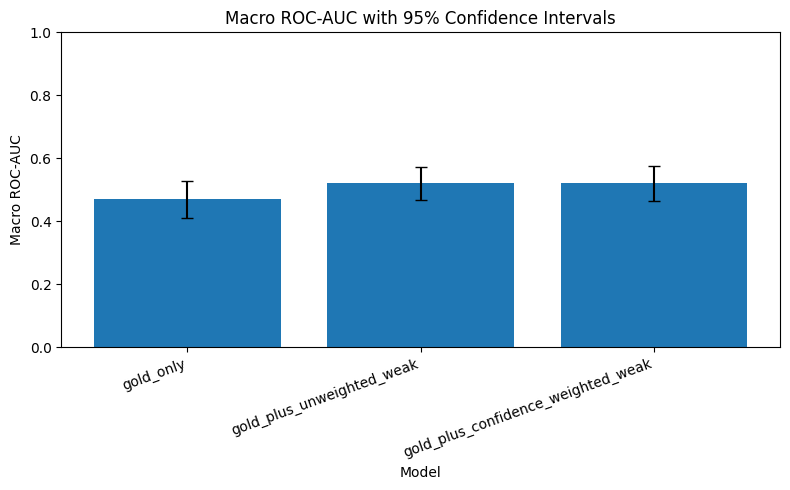

In [22]:
import matplotlib.pyplot as plt
import numpy as np

# Keep only Macro ROC-AUC rows
auc_ci = ci[ci["metric"] == "macro_roc_auc"].copy()

# Calculate asymmetric error bars
lower_error = auc_ci["estimate"] - auc_ci["ci_2_5"]
upper_error = auc_ci["ci_97_5"] - auc_ci["estimate"]

errors = np.vstack([lower_error, upper_error])

plt.figure(figsize=(8, 5))

plt.bar(
    auc_ci["mode"],
    auc_ci["estimate"],
    yerr=errors,
    capsize=4
)

plt.ylabel("Macro ROC-AUC")
plt.xlabel("Model")
plt.title("Macro ROC-AUC with 95% Confidence Intervals")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(
    "/kaggle/working/figs/final_auc_with_ci.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [23]:
for f in os.listdir(P["15"]):
    if f.endswith(".png"):
        print(f)

15_attention_concentration.png
15_nb12_attention_concentration.png
15_nb12_top_series_attention.png
15_nb12_top_slice_attention.png
15_top_series_attention.png
15_top_slice_attention.png


In [24]:
import shutil
from pathlib import Path

fig_dir = Path("/kaggle/working/figs")
fig_dir.mkdir(parents=True, exist_ok=True)

attention_figures = [
    "15_nb12_attention_concentration.png",
    "15_nb12_top_series_attention.png",
    "15_nb12_top_slice_attention.png"
]

for f in attention_figures:
    src = P["15"] / f
    dst = fig_dir / f

    if src.exists():
        shutil.copy2(src, dst)
        print("Copied:", f)
    else:
        print("File not found:", src)

Copied: 15_nb12_attention_concentration.png
Copied: 15_nb12_top_series_attention.png
Copied: 15_nb12_top_slice_attention.png


In [25]:
for f in os.listdir(P["16"]):
    if f.endswith(".png"):
        print(f)

16_model_comparison.png


In [26]:
for notebook in ["14", "15", "16"]:
    print(f"\nNotebook {notebook}")
    for root, dirs, files in os.walk(P[notebook]):
        for f in files:
            if f.endswith(".png"):
                print(os.path.join(root, f))


Notebook 14
/kaggle/input/notebooks/richashanbhag/14-evaluation/14_evaluation/overall_metric_comparison.png
/kaggle/input/notebooks/richashanbhag/14-evaluation/14_evaluation/per_finding_brier_score_heatmap.png
/kaggle/input/notebooks/richashanbhag/14-evaluation/14_evaluation/per_finding_ece_heatmap.png
/kaggle/input/notebooks/richashanbhag/14-evaluation/14_evaluation/per_finding_f1_heatmap.png
/kaggle/input/notebooks/richashanbhag/14-evaluation/14_evaluation/per_finding_pr_auc_heatmap.png
/kaggle/input/notebooks/richashanbhag/14-evaluation/14_evaluation/reliability_diagrams.png

Notebook 15
/kaggle/input/notebooks/shambhavisinha254/15-explainability/15_explainability/15_attention_concentration.png
/kaggle/input/notebooks/shambhavisinha254/15-explainability/15_explainability/15_nb12_attention_concentration.png
/kaggle/input/notebooks/shambhavisinha254/15-explainability/15_explainability/15_nb12_top_series_attention.png
/kaggle/input/notebooks/shambhavisinha254/15-explainability/15_expl

In [29]:
import shutil
from pathlib import Path

fig_dir = Path("/kaggle/working/figs")
fig_dir.mkdir(parents=True, exist_ok=True)

figures = {
    # Notebook 14
    "14_overall_metric_comparison.png": P["14"] / "overall_metric_comparison.png",
    "14_per_finding_f1_heatmap.png": P["14"] / "per_finding_f1_heatmap.png",
    "14_per_finding_pr_auc_heatmap.png": P["14"] / "per_finding_pr_auc_heatmap.png",
    "14_reliability_diagrams.png": P["14"] / "reliability_diagrams.png",

    # Notebook 15
    "15_attention_concentration.png": P["15"] / "15_nb12_attention_concentration.png",
    "15_top_series_attention.png": P["15"] / "15_nb12_top_series_attention.png",
    "15_top_slice_attention.png": P["15"] / "15_nb12_top_slice_attention.png",

    # Notebook 16
    "16_model_comparison.png": P["16"] / "16_model_comparison.png"
}

for name, src in figures.items():
    if src.exists():
        shutil.copy2(src, fig_dir / name)
        print("Copied:", name)
    else:
        print("NOT FOUND:", src)

print("\nFinal figure count:", len(list(fig_dir.glob("*.png"))))

Copied: 14_overall_metric_comparison.png
Copied: 14_per_finding_f1_heatmap.png
Copied: 14_per_finding_pr_auc_heatmap.png
Copied: 14_reliability_diagrams.png
Copied: 15_attention_concentration.png
Copied: 15_top_series_attention.png
Copied: 15_top_slice_attention.png
Copied: 16_model_comparison.png

Final figure count: 12



14_overall_metric_comparison.png


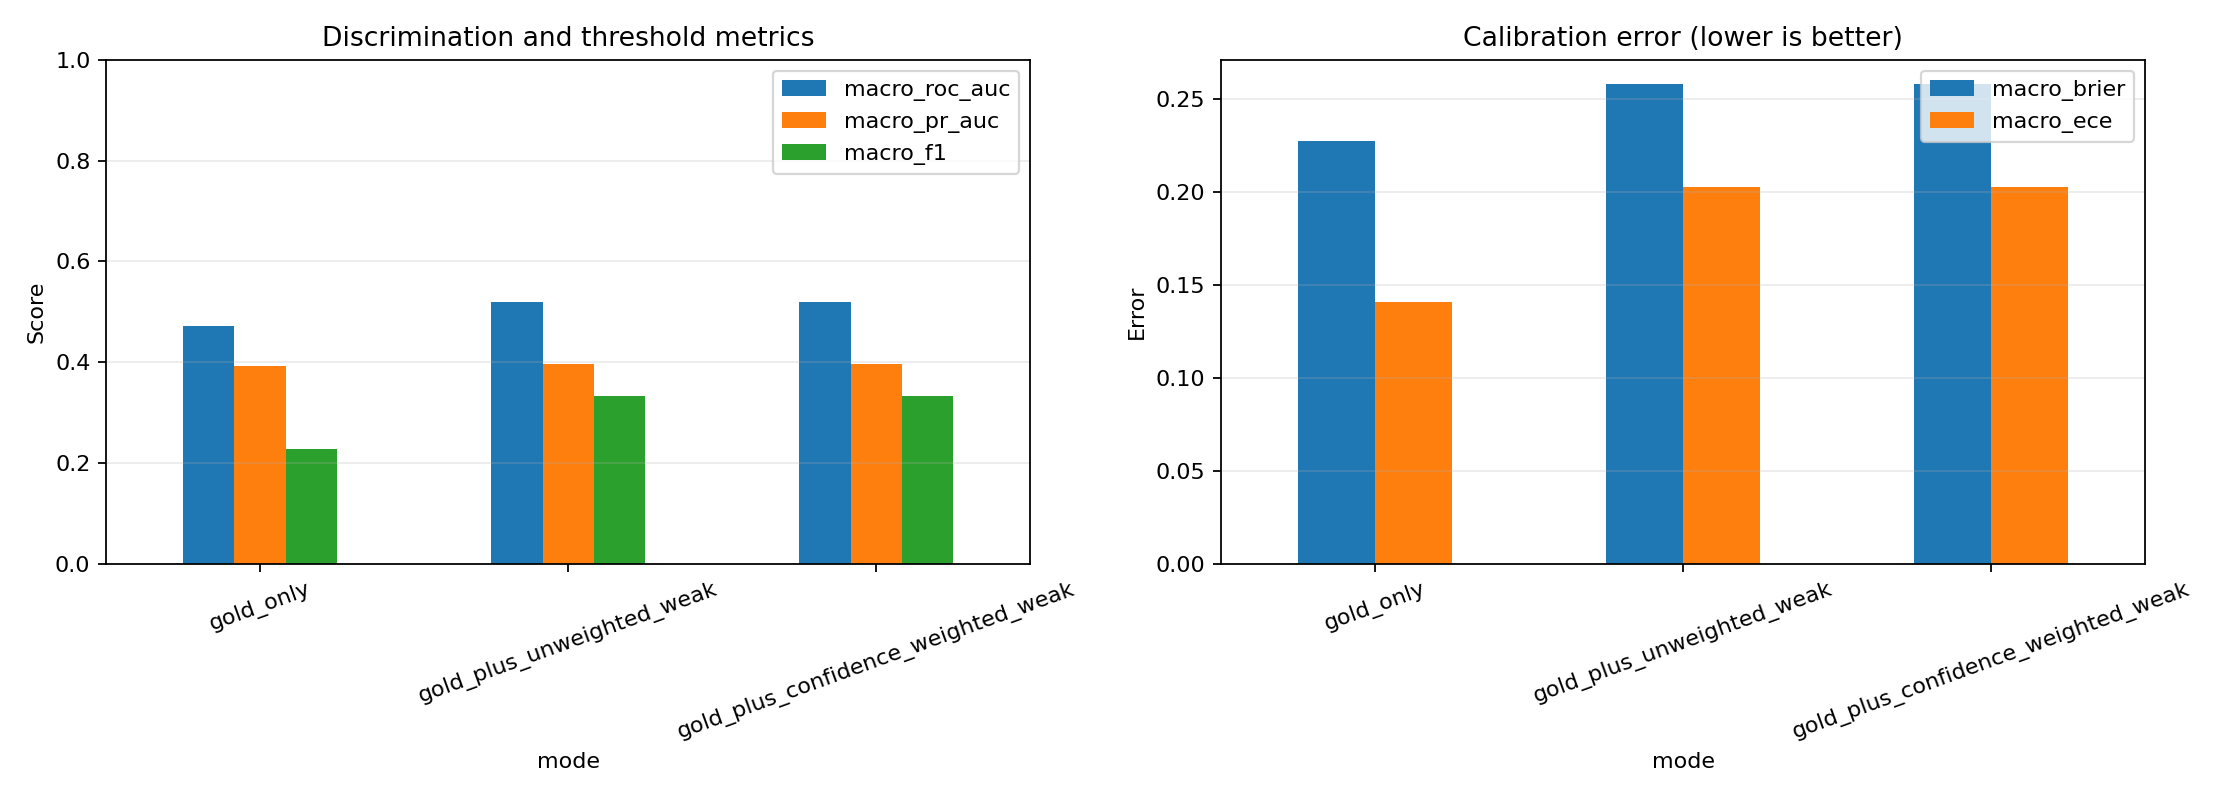


14_per_finding_f1_heatmap.png


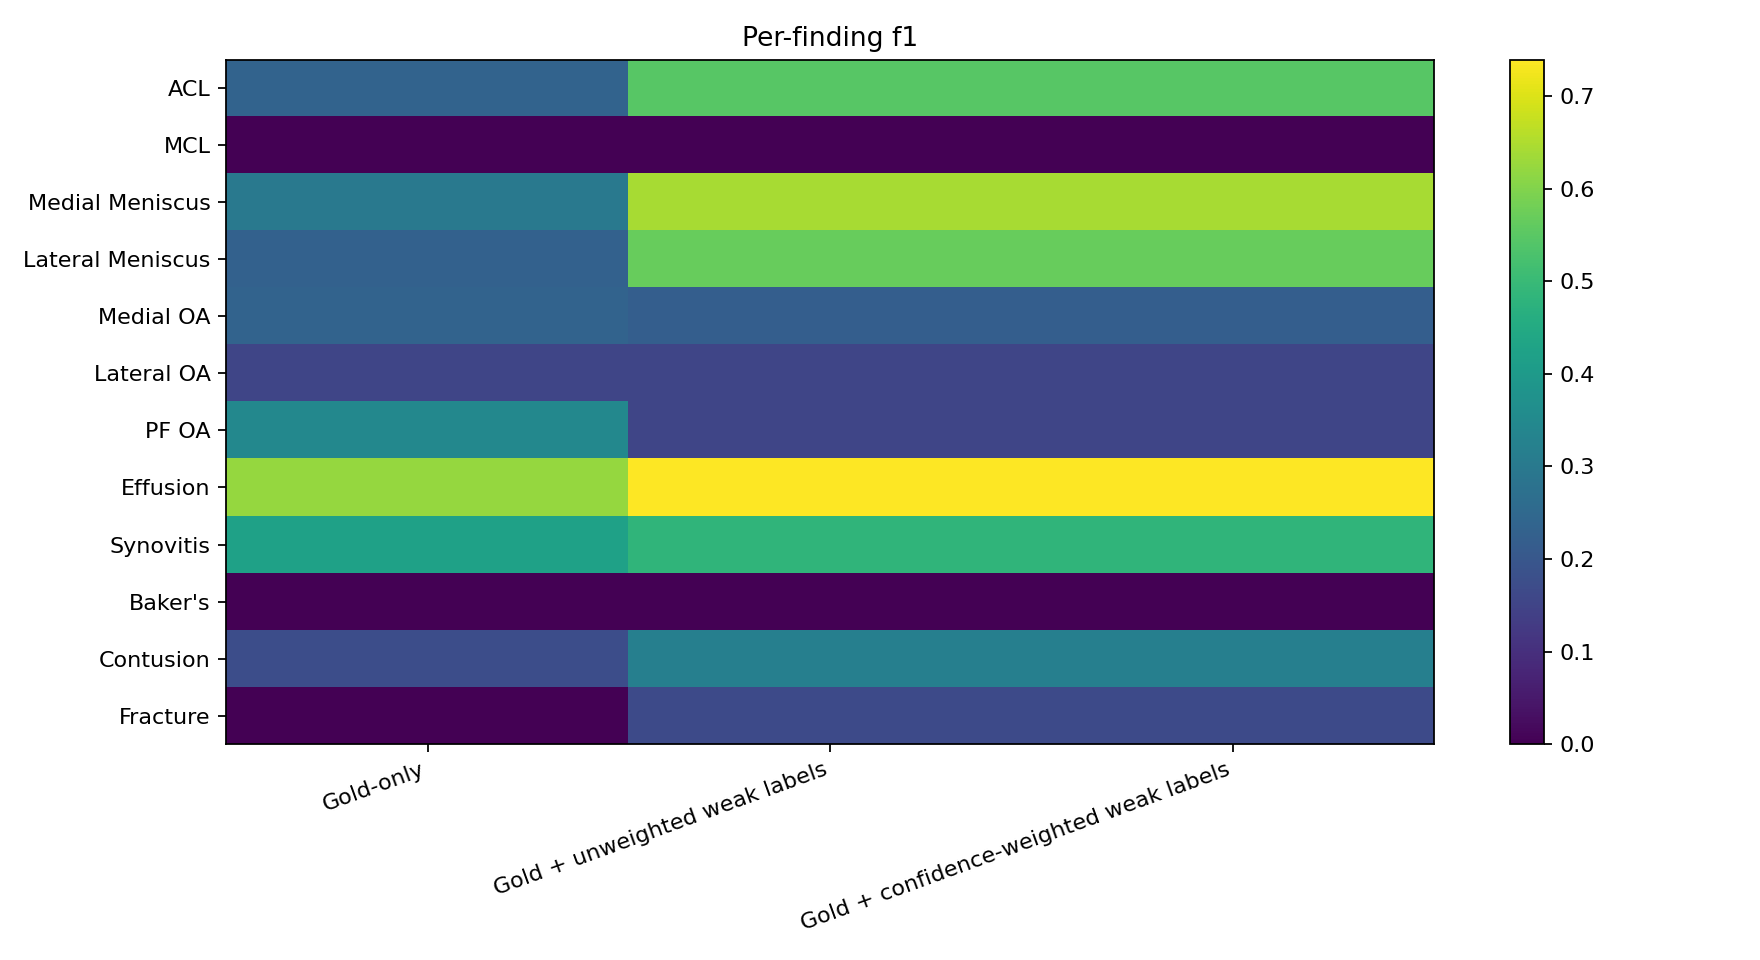


14_per_finding_pr_auc_heatmap.png


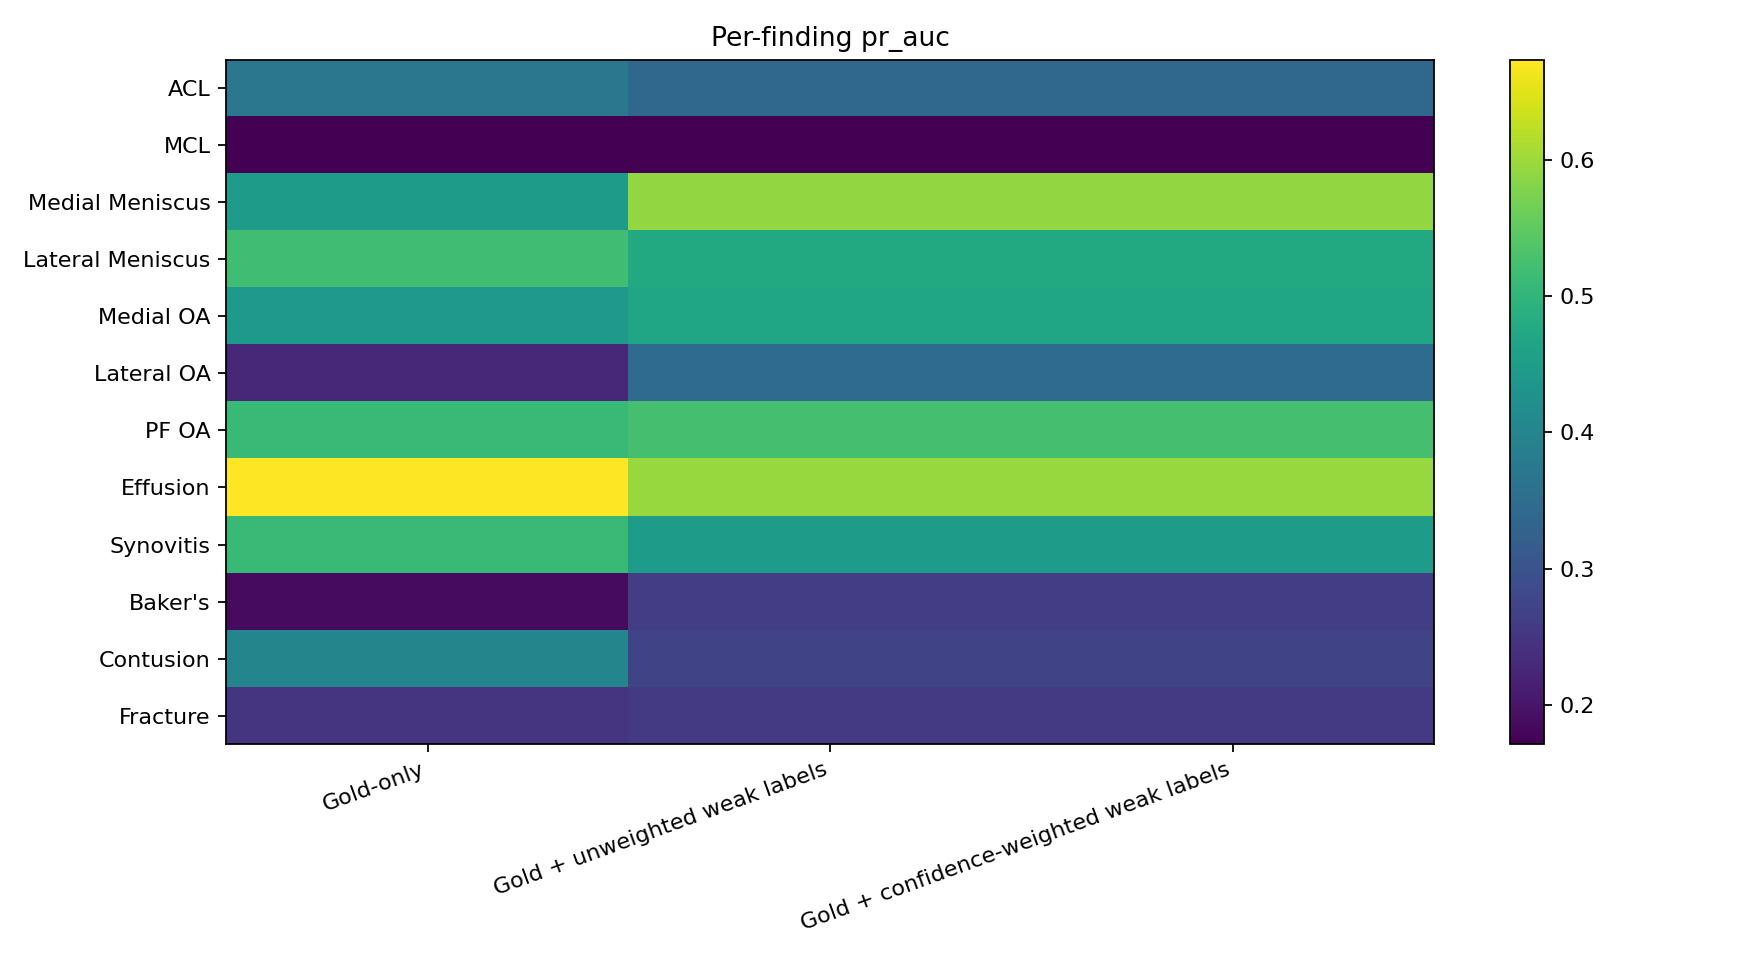


14_reliability_diagrams.png


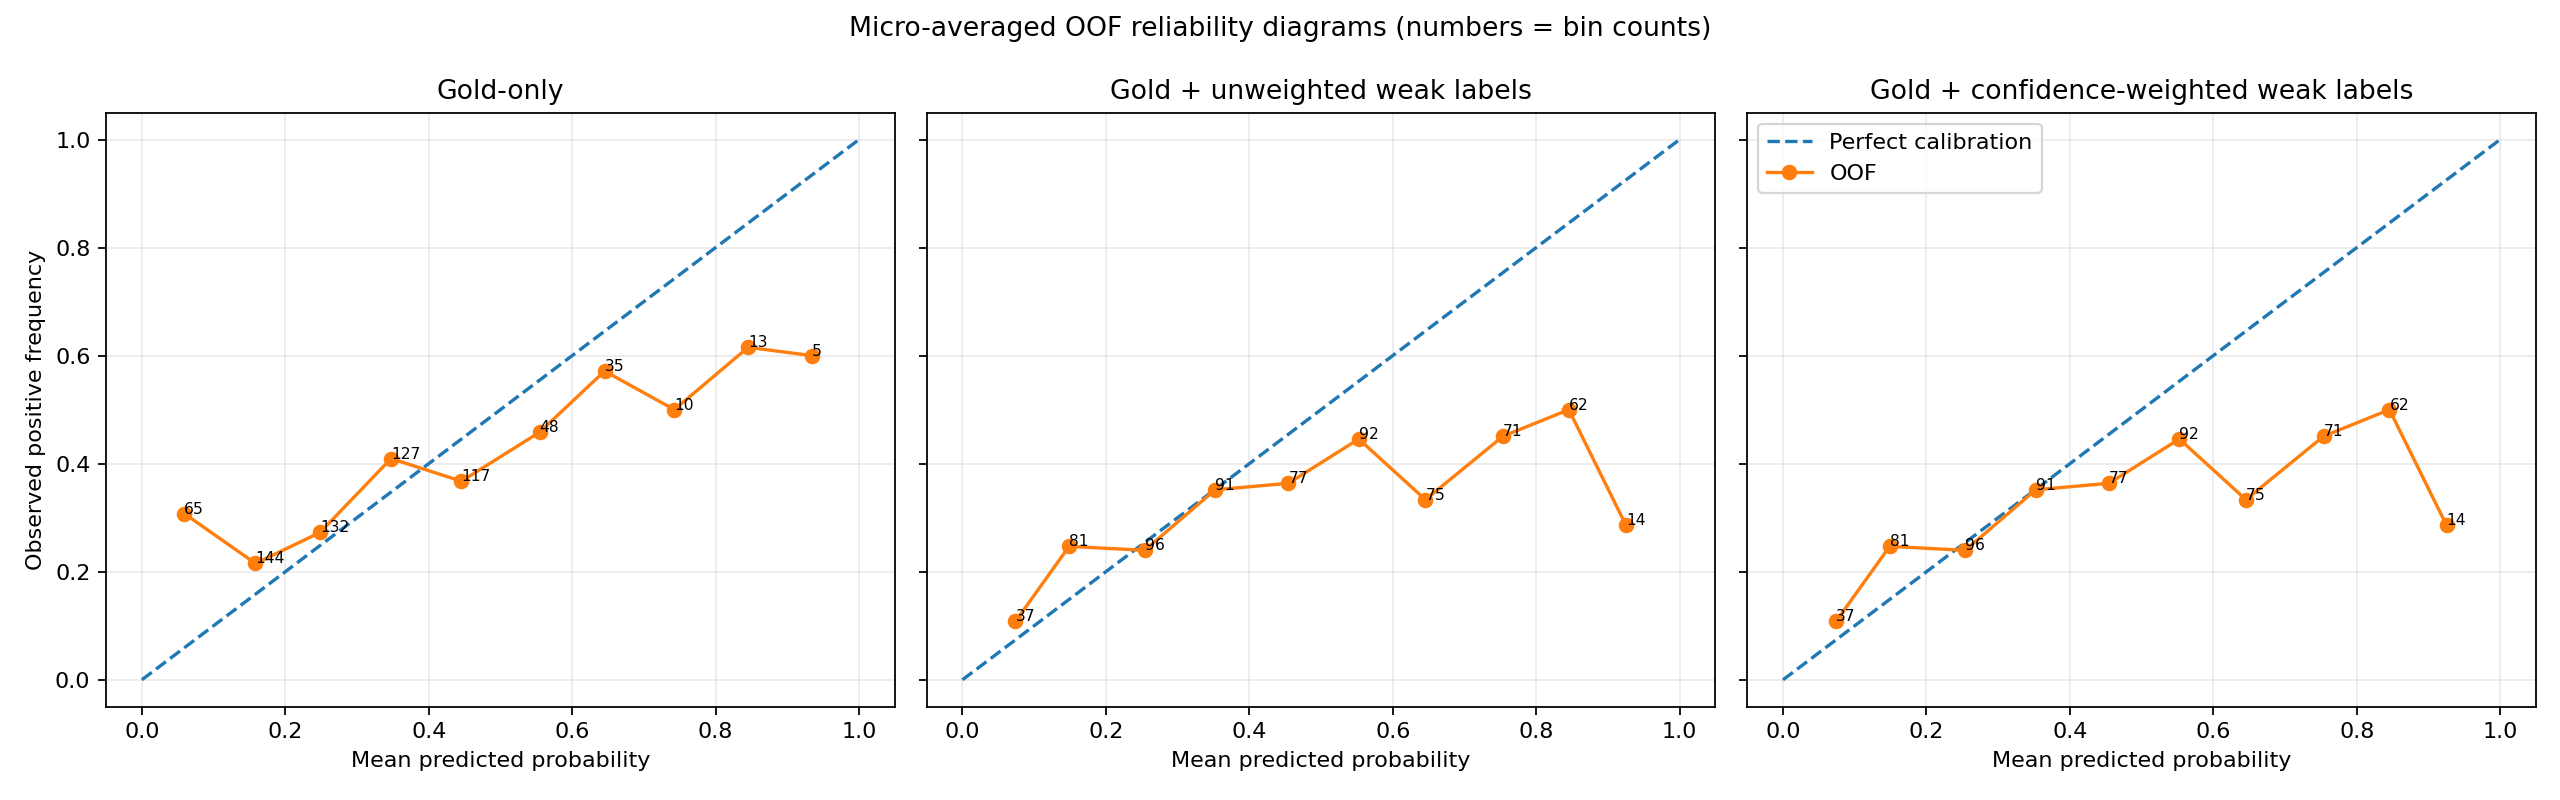


15_attention_concentration.png


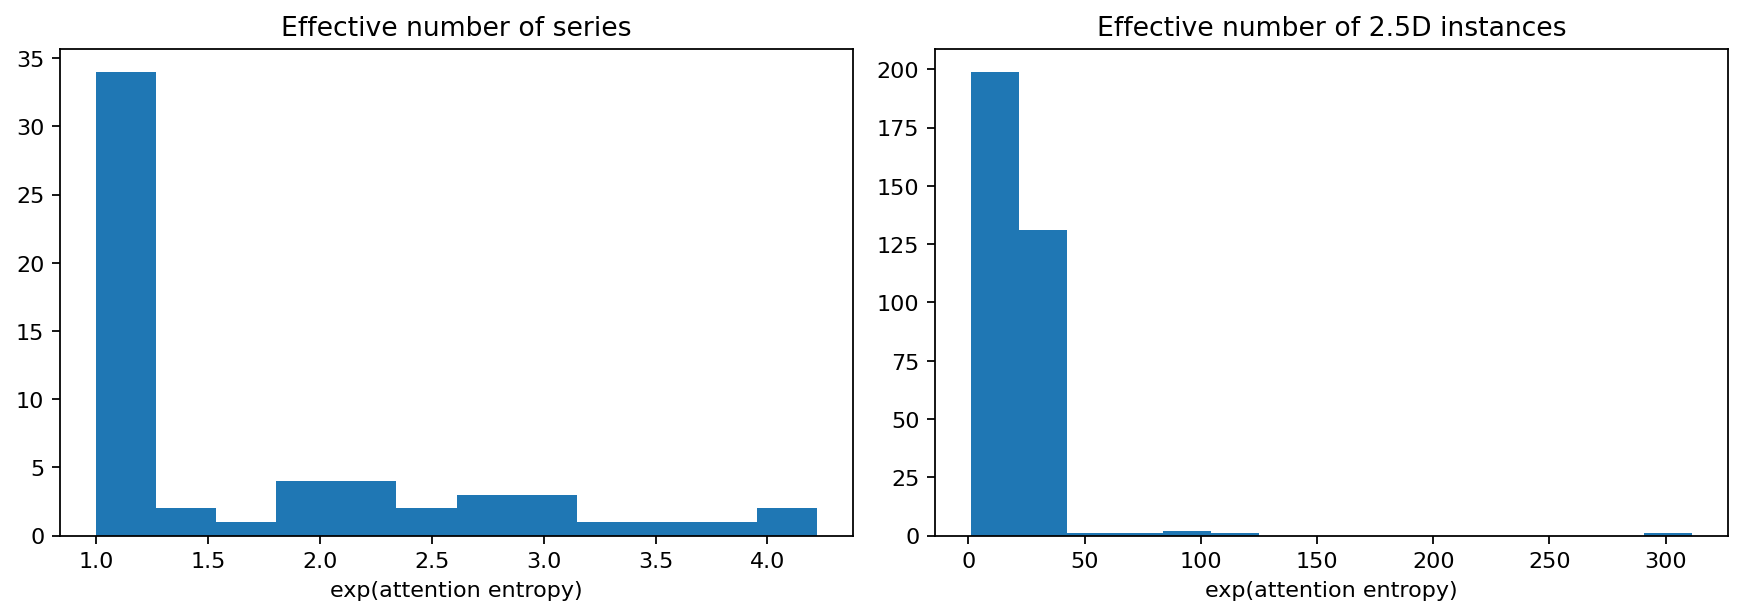


15_nb12_attention_concentration.png


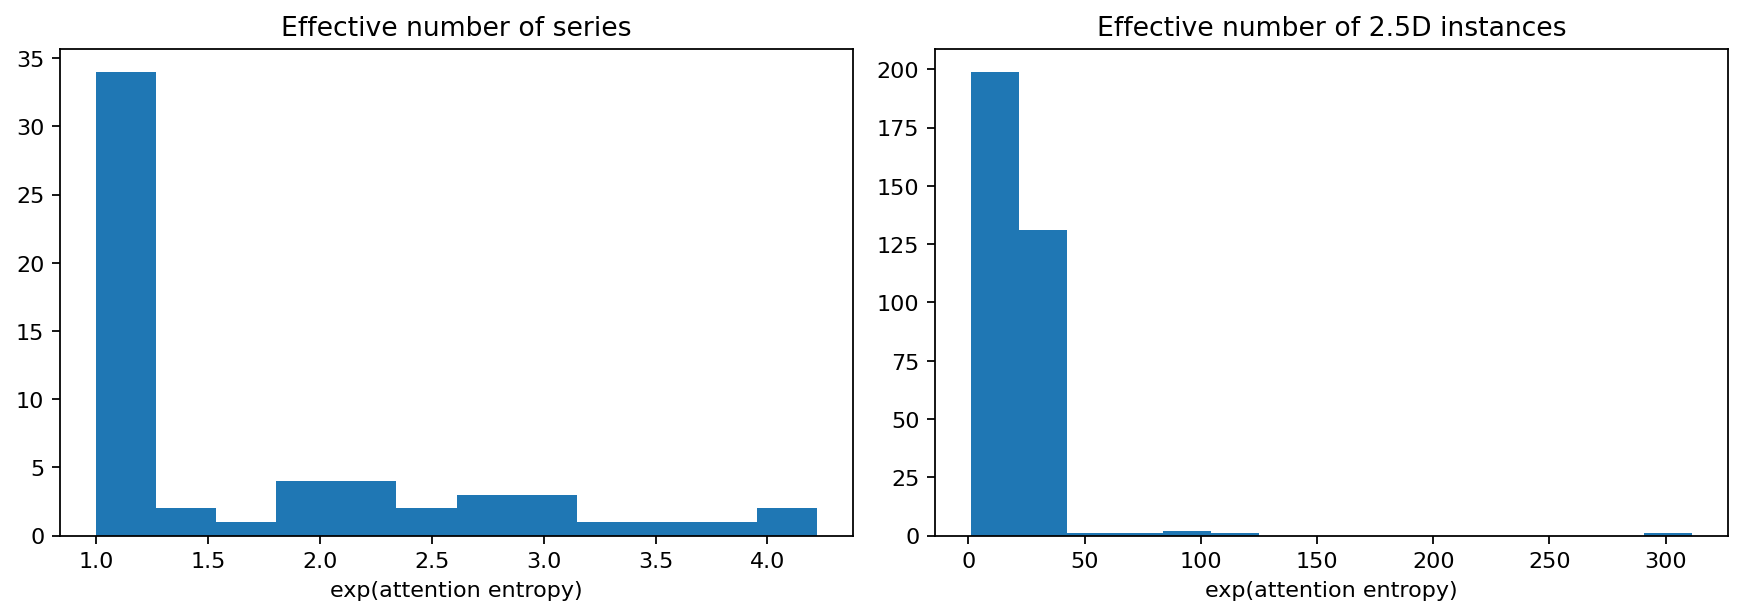


15_nb12_top_series_attention.png


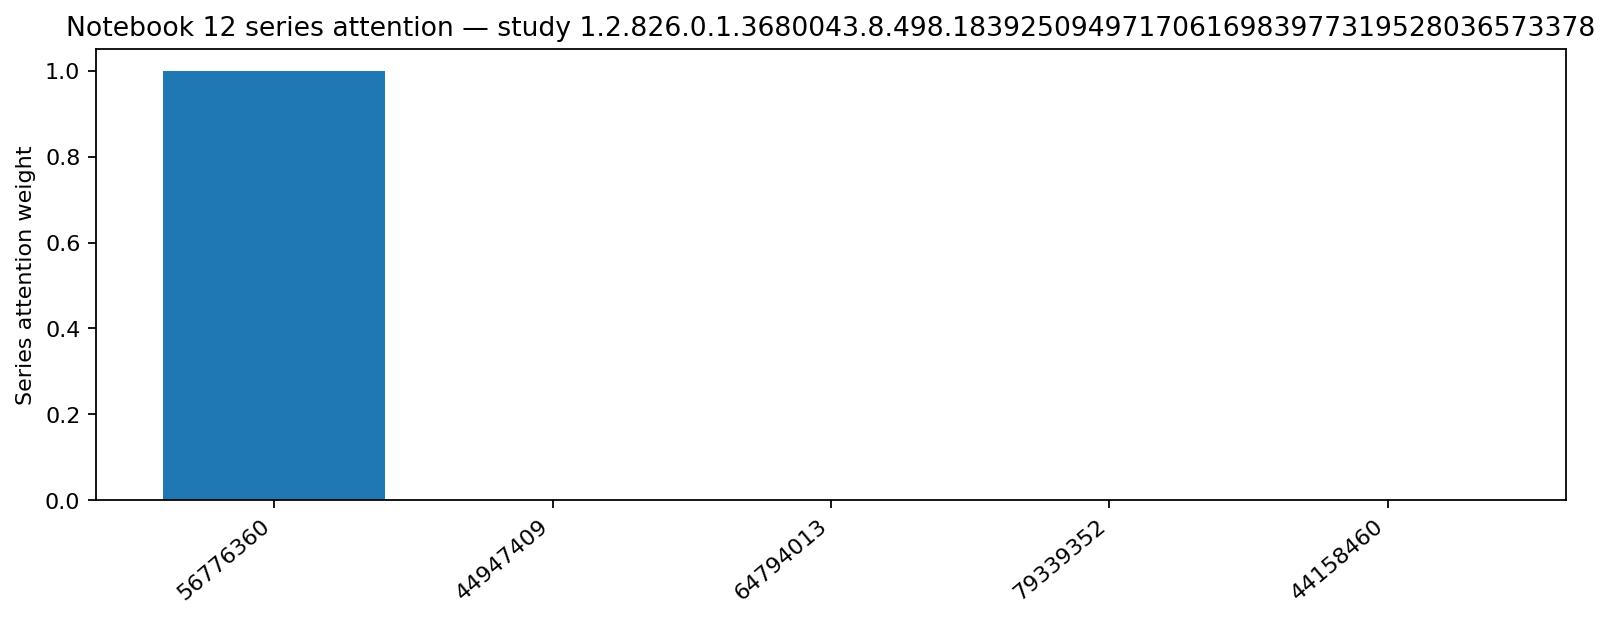


15_nb12_top_slice_attention.png


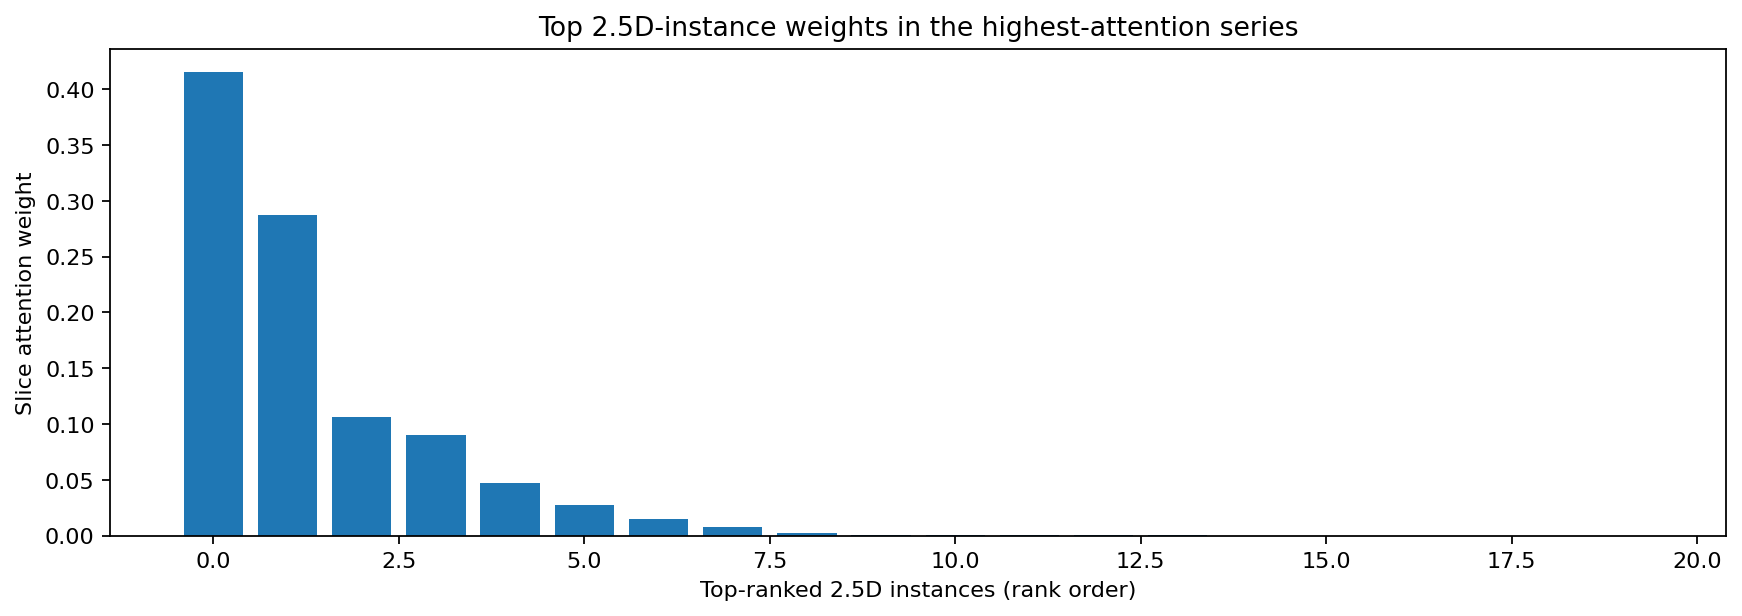


15_top_series_attention.png


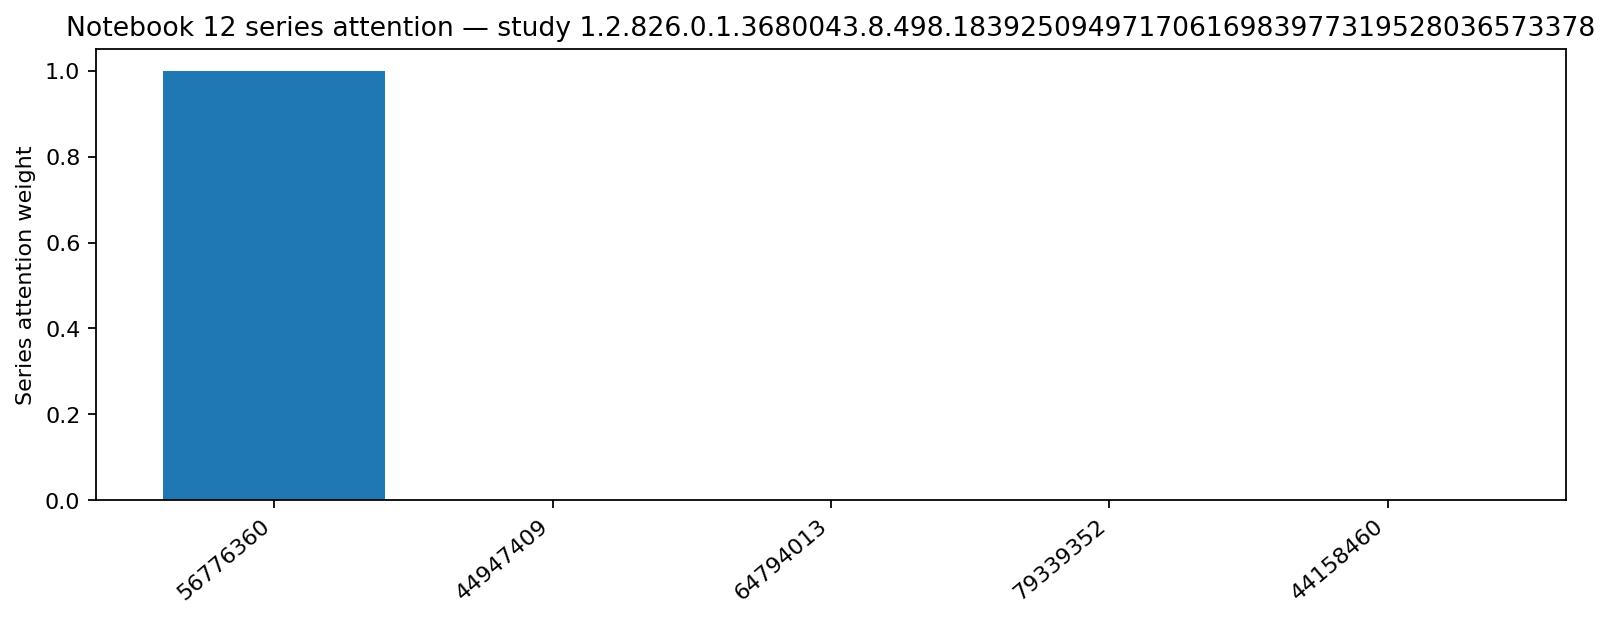


15_top_slice_attention.png


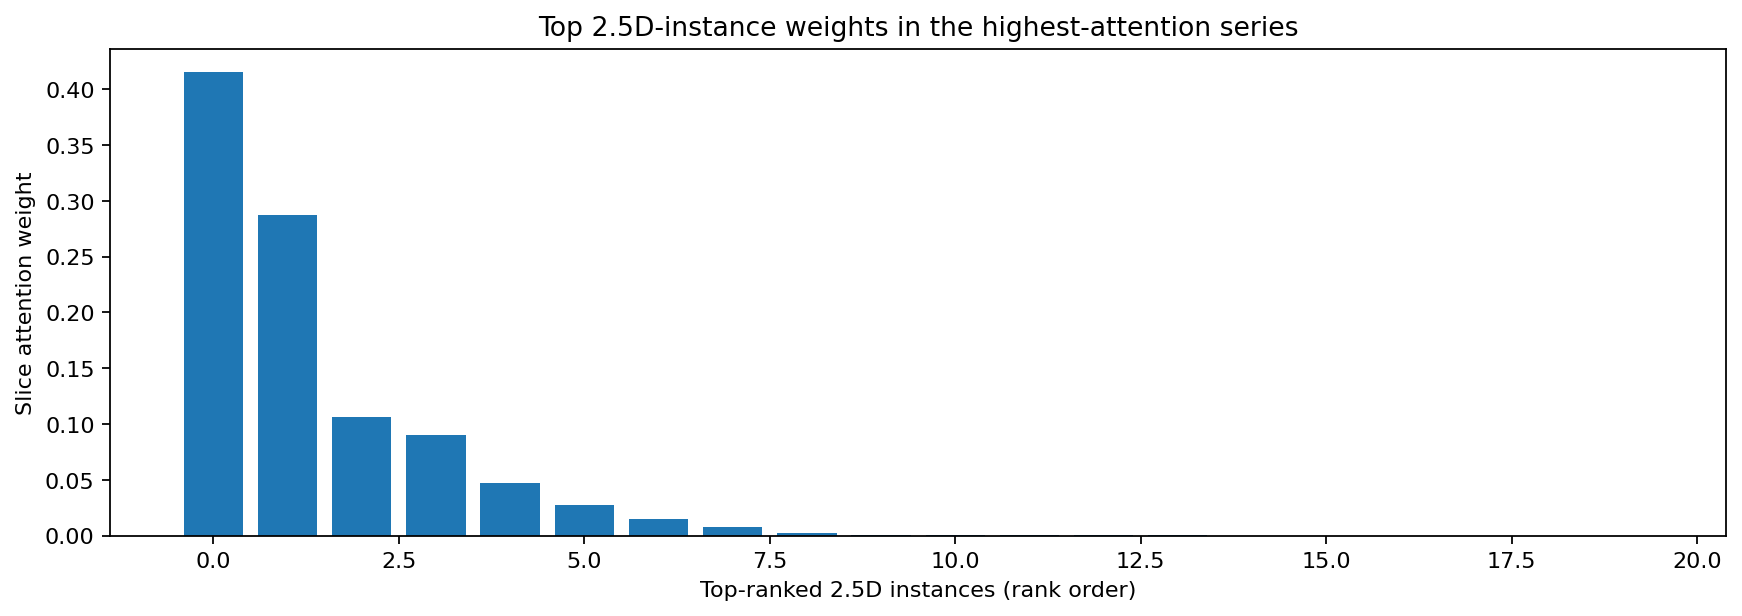


16_model_comparison.png


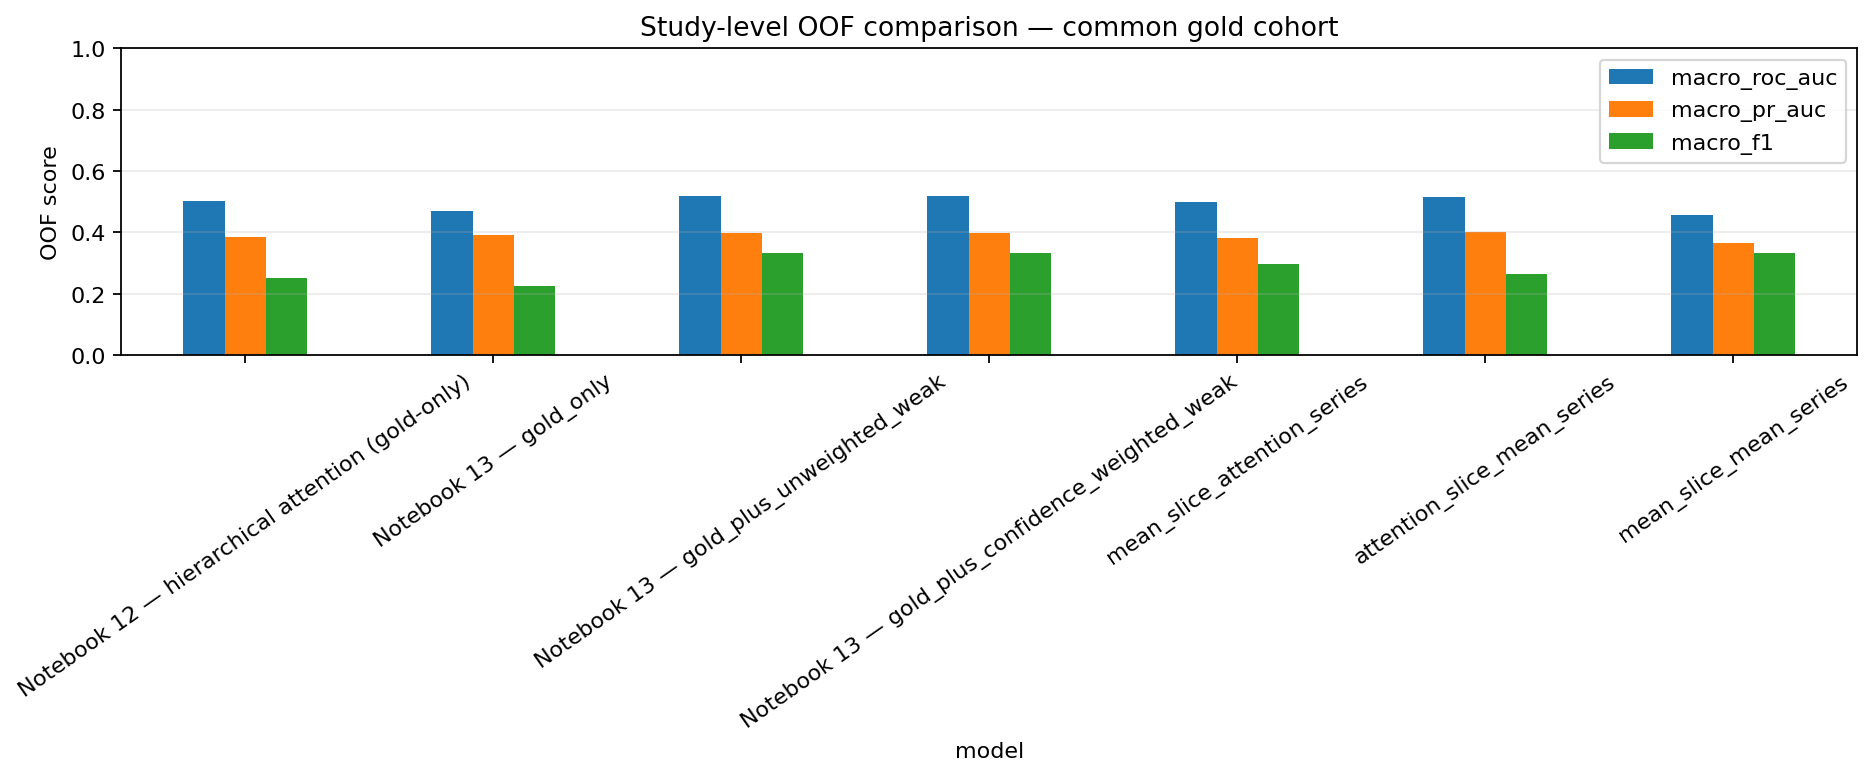


final_auc_with_ci.png


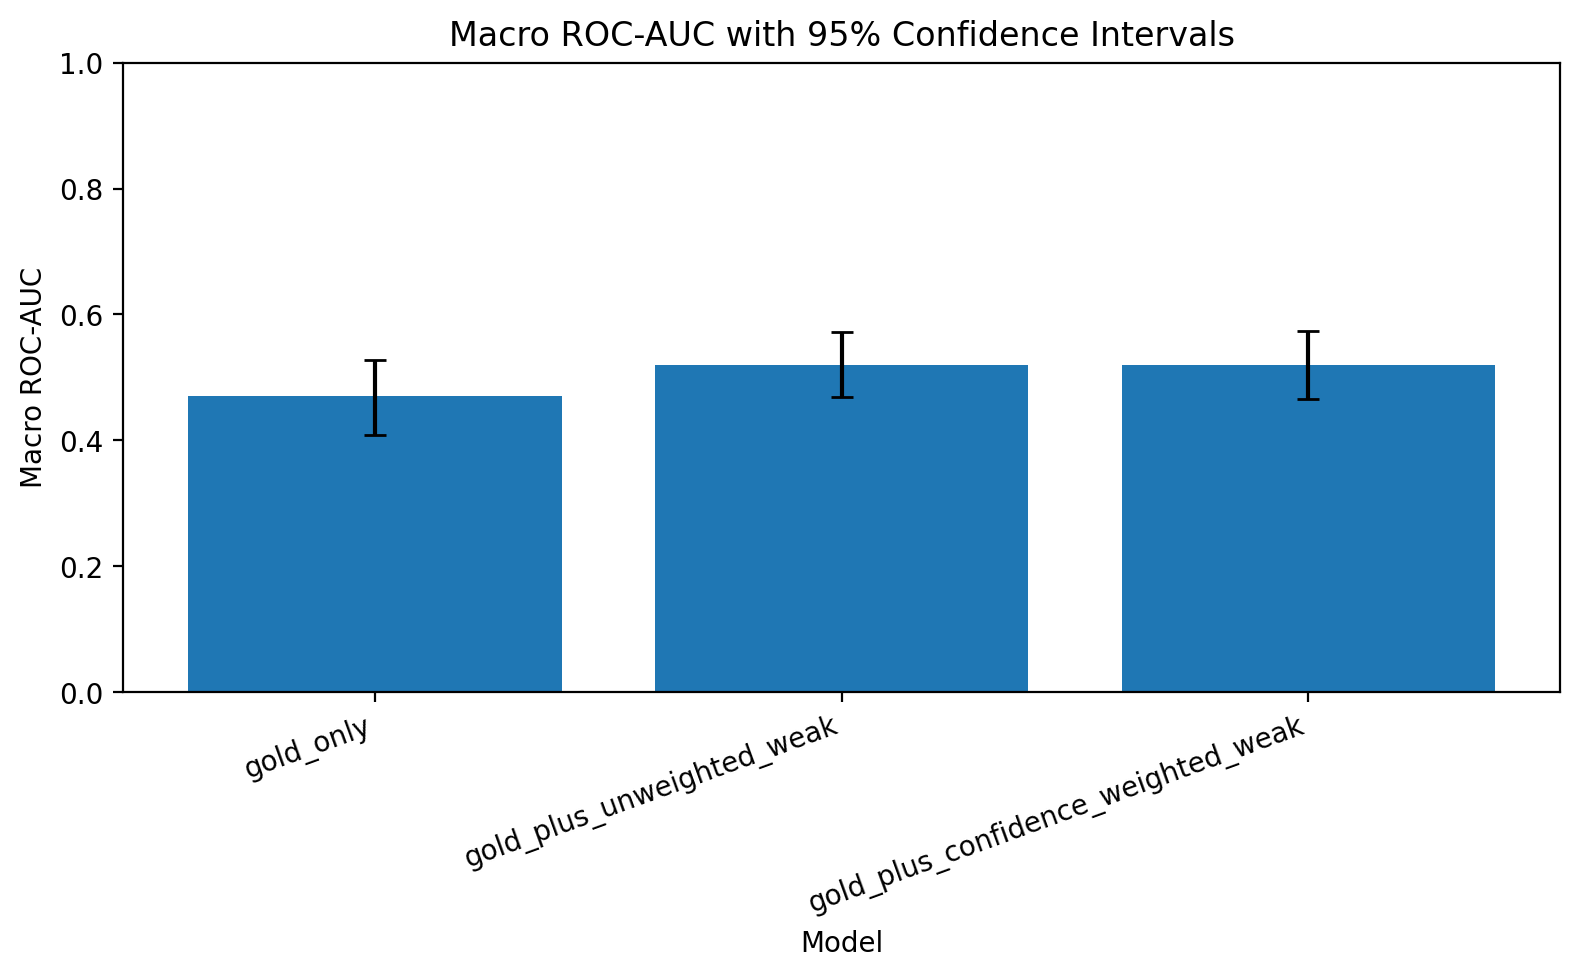

In [30]:
from IPython.display import display, Image
from pathlib import Path

fig_dir = Path("/kaggle/working/figs")

for f in sorted(fig_dir.glob("*.png")):
    print(f"\n{f.name}")
    display(Image(filename=str(f)))

In [33]:
print("OVERALL METRICS")
display(pd.read_csv(P["14"] / "overall_metrics.csv"))

print("CONFIDENCE INTERVALS")
display(pd.read_csv(P["14"] / "bootstrap_confidence_intervals.csv"))

print("PAIRED BOOTSTRAP")
display(pd.read_csv(P["14"] / "paired_bootstrap_differences.csv"))

print("ABLATION")
display(pd.read_csv(P["16"] / "16_pooling_ablation_comparison.csv"))

print("ERROR COUNTS")
display(pd.read_csv(P["16"] / "16_error_counts_by_label.csv"))

OVERALL METRICS


,mode,macro_roc_auc,macro_pr_auc,macro_f1,macro_precision,macro_recall,macro_brier,macro_ece,hamming_loss,micro_f1,exact_match_accuracy
0,gold_only,0.470951,0.392358,0.226700,0.455417,0.182383,0.227244,0.140827,0.337644,0.330484,0.0
1,gold_plus_unweighted_weak,0.520096,0.396903,0.333171,0.357567,0.434800,0.258092,0.202638,0.413793,0.480144,0.0
2,gold_plus_confidence_weighted_weak,0.520096,0.396903,0.333171,0.357567,0.434800,0.258092,0.202638,0.413793,0.480144,0.0


CONFIDENCE INTERVALS


,mode,metric,estimate,ci_2_5,ci_97_5,bootstrap_replicates
0,gold_only,macro_roc_auc,0.470951,0.409235,0.526983,2000
1,gold_only,macro_pr_auc,0.392358,0.347796,0.472964,2000
2,gold_only,macro_f1,0.226700,0.145733,0.296363,2000
3,gold_only,macro_brier,0.227244,0.208161,0.246457,2000
4,gold_only,macro_ece,0.140827,0.142591,0.205285,2000
5,gold_plus_unweighted_weak,macro_roc_auc,0.520096,0.468934,0.572918,2000
6,gold_plus_unweighted_weak,macro_pr_auc,0.396903,0.355059,0.482693,2000
7,gold_plus_unweighted_weak,macro_f1,0.333171,0.270769,0.394436,2000
8,gold_plus_unweighted_weak,macro_brier,0.258092,0.239512,0.276964,2000
9,gold_plus_unweighted_weak,macro_ece,0.202638,0.193319,0.261920,2000


PAIRED BOOTSTRAP


,comparison,metric,difference,ci_2_5,ci_97_5,bootstrap_replicates,direction_of_benefit
0,gold_plus_unweighted_weak vs gold_only,macro_roc_auc,0.049144,-0.023399,0.123188,2000,higher
1,gold_plus_unweighted_weak vs gold_only,macro_pr_auc,0.004546,-0.057367,0.073363,2000,higher
2,gold_plus_unweighted_weak vs gold_only,macro_f1,0.106471,0.005461,0.214172,2000,higher
3,gold_plus_unweighted_weak vs gold_only,macro_brier,0.030849,0.004249,0.055870,2000,lower
4,gold_plus_unweighted_weak vs gold_only,macro_ece,0.061812,0.013001,0.097388,2000,lower
5,gold_plus_confidence_weighted_weak vs gold_only,macro_roc_auc,0.049144,-0.023778,0.127170,2000,higher
6,gold_plus_confidence_weighted_weak vs gold_only,macro_pr_auc,0.004546,-0.059725,0.071348,2000,higher
7,gold_plus_confidence_weighted_weak vs gold_only,macro_f1,0.106471,0.003565,0.212862,2000,higher
8,gold_plus_confidence_weighted_weak vs gold_only,macro_brier,0.030849,0.004317,0.057267,2000,lower
9,gold_plus_confidence_weighted_weak vs gold_only,macro_ece,0.061812,0.011374,0.098675,2000,lower


ABLATION


,model,macro_roc_auc,macro_pr_auc,macro_f1,micro_f1,hamming_loss
0,Notebook 12 — hierarchical attention (gold-only),0.501211,0.385464,0.250811,0.341969,0.364943
1,Notebook 13 — gold_only,0.470951,0.392358,0.226700,0.330484,0.337644
2,Notebook 13 — gold_plus_unweighted_weak,0.520096,0.396903,0.333171,0.480144,0.413793
3,Notebook 13 — gold_plus_confidence_weighted_weak,0.520096,0.396903,0.333171,0.480144,0.413793
4,mean_slice_attention_series,0.498008,0.383255,0.296774,0.397590,0.431034
5,attention_slice_mean_series,0.515732,0.401569,0.263458,0.395745,0.408046
6,mean_slice_mean_series,0.457205,0.365604,0.333024,0.430189,0.433908


ERROR COUNTS


,finding,FN,FP,TN,TP
0,ACL,13,16,18,11
1,Baker's,12,0,46,0
2,Contusion,15,8,31,4
3,Effusion,7,15,8,28
4,Fracture,16,7,33,2
5,Lateral Meniscus,21,0,35,2
6,Lateral OA,10,4,43,1
7,MCL,8,2,47,1
8,Medial Meniscus,18,10,22,8
9,Medial OA,11,4,39,4


### Summary of Results

- **Model performance:** The project evaluated EfficientNet-B0, ViT-S/16, and DINOv2-based multiple-instance learning approaches for knee MRI abnormality detection across 12 findings.

- **Baseline comparison:** EfficientNet-B0 achieved a macro ROC-AUC of 0.5723 ± 0.0690, while ViT-S/16 achieved 0.5591 ± 0.0504. Their macro F1 scores were 0.2114 ± 0.0442 and 0.2560 ± 0.0711, respectively.

- **Proposed approach:** DINOv2-based slice attention, series attention, and hierarchical attention models were investigated to aggregate MRI information at different levels.

- **Weak supervision:** Radiology report-derived pseudo-labels were explored to make use of the larger report-only dataset. Their effect on model performance requires further evaluation.

- **Ablation study:** Different attention and pooling strategies were compared to understand their contribution to model performance.

- **Explainability:** Attention visualisations were generated to examine the contribution of individual slices and MRI series to study-level predictions.

- **Error analysis:** False negatives were the dominant error type, with 174 false negatives compared with 80 false positives across the 12 findings. Synovitis and meniscus abnormalities had particularly high false-negative counts. Baker's cyst detection produced no true positives, while effusion showed comparatively better detection.

- **Limitations:** The structured labelled dataset contained only 58 fully labelled studies. Therefore, the findings should be interpreted as exploratory. Further validation using a larger labelled dataset is required.